# Zomato - Part 5 : Restaurant Recommendation System

Finally the main thing ;) Everything we did in Part 1 - 4 was to reach here.

### Types of recommendation systems :

| Type | Idea | Can we do it ? |
|---|---|---|
| **Popularity based** | recommend what is good for everyone | Yes |
| **Content based** | "*you liked X, here are restaurants similar to X*" | Yes |
| **Collaborative filtering** | "*users like you also liked Y*" | **No** -> needs user-restaurant interaction data (which user rated what), our dataset doesn't have user ids |
| **Hybrid** | mix of above | Yes (popularity + content) |

-------------------------------------------------------

### Plan :
1. **Popularity based** recommender with filters (location, cuisine, budget ...)
2. **Content based** recommender (TF-IDF + Cosine Similarity)
3. **Hybrid** recommender (similarity + quality score)
4. **Preference based** search : user just types what they want (eg : *"italian pizza in indiranagar under 1000"*)
5. **Evaluation** of all approaches (offline metrics, since we don't have real user feedback)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
sns.set_style('whitegrid')
sns.set_palette("husl")

plt.rcParams['figure.figsize'] = (12,6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
%matplotlib inline

pd.set_option("display.max_colwidth", 45)

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

In [5]:
rest = pd.read_csv("restaurants_final.csv")
print("Shape: ", rest.shape)

Shape:  (12463, 29)


Quick reminder of the important columns from previous notebooks :
- `quality_score` : weighted rating (rated) OR shrunk predicted rating (NEW restaurants) -> **how good** is the restaurant
- `tags` : text description (cuisines + rest type + meal types + price + location) -> **what** is the restaurant
- `is_rated` : 0 means NEW restaurant

In [6]:
show_cols = ["name", "location", "rest_type", "cuisines", "cost_for_two", "rate", "votes", "quality_score"]

rest[show_cols + ["tags"]].head()

,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,tags
0,#Feeltheroll,Bellandur,Quick Bites,Fast Food,200.0,3.4,7,3.598,fast_food rt_quick_bites meal_delivery pr...
1,#L-81 Cafe,Hsr,Quick Bites,"Fast Food, Beverages",400.0,3.9,48,3.755,fast_food beverages rt_quick_bites meal_d...
2,#Refuel,Bannerghatta Road,Cafe,"Cafe, Beverages",400.0,3.7,37,3.655,cafe beverages rt_cafe meal_cafes meal_de...
3,#Vibes Restro,Electronic City,Casual Dining,"Continental, Chinese, Italian",700.0,NaN,0,3.422,continental chinese italian rt_casual_din...
4,'Brahmins' Thatte Idli,Basaveshwara Nagar,Quick Bites,South Indian,100.0,NaN,0,3.607,south_indian rt_quick_bites meal_dine_out...


------------------------------------------------------------------------------

# 1. Popularity Based Recommender

Simplest one : filter by what user wants -> sort by `quality_score`.

This is what zomato shows when you open the app and haven't searched anything (*"Top restaurants near you"*).

In [7]:
def recommend_popular(location=None, cuisine=None, max_cost=None, min_cost=None,
                      online_order=None, book_table=None, n=10):

    result = rest.copy()

    if location is not None:
        result = result[result["location"].str.lower() == location.lower()]

    if cuisine is not None:
        result = result[result["cuisines"].str.lower().str.contains(cuisine.lower(), regex=False)]

    if max_cost is not None:
        result = result[result["cost_for_two"] <= max_cost]

    if min_cost is not None:
        result = result[result["cost_for_two"] >= min_cost]

    if online_order is not None:
        result = result[result["online_order"] == int(online_order)]

    if book_table is not None:
        result = result[result["book_table"] == int(book_table)]

    if len(result) == 0:
        print("No restaurant found with these filters :(")
        return result

    result = result.sort_values("quality_score", ascending=False)
    result = result.drop_duplicates(subset="name", keep="first")   # only best outlet of a chain
    return result[show_cols].head(n).reset_index(drop=True)

#### Example 1 : Top 10 restaurants in whole Bangalore

In [8]:
recommend_popular()

,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score
0,Byg Brewski Brewing Company,Sarjapur Road,Microbrewery,"Continental, North Indian, Italian, South...",1600.0,4.9,16832,4.896
1,Ab'S - Absolute Barbecues,Btm,Casual Dining,"European, Mediterranean, North Indian, Bbq",1600.0,4.9,6490,4.890
2,Flechazo,Whitefield,Casual Dining,"Asian, Mediterranean, North Indian, Bbq",1400.0,4.9,3004,4.878
3,Asia Kitchen By Mainland China,Koramangala 5Th Block,"Casual Dining, Bar","Asian, Chinese, Thai, Momos",1500.0,4.9,2256,4.871
4,Milano Ice Cream,Indiranagar,Dessert Parlor,"Ice Cream, Desserts",400.0,4.9,2090,4.868
5,Punjab Grill,Malleshwaram,Casual Dining,"North Indian, Mughlai",2000.0,4.9,1985,4.867
6,Belgian Waffle Factory,Brigade Road,Dessert Parlor,Desserts,400.0,4.9,1750,4.863
7,The Black Pearl,Marathahalli,"Casual Dining, Bar","North Indian, European, Mediterranean, Bbq",1500.0,4.8,7284,4.792
8,Chili'S American Grill & Bar,Malleshwaram,"Casual Dining, Bar","American, Tex-Mex, Burger, Bbq, Mexican",1400.0,4.8,6470,4.790
9,The Boozy Griffin,Marathahalli,Pub,"European, Continental",1800.0,4.8,4705,4.787


#### Example 2 : Best Biryani in BTM under Rs.600 (for two) with online order

In [9]:
recommend_popular(location="Btm", cuisine="Biryani", max_cost=600, online_order=True)

,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score
0,Eat.Fit,Btm,Delivery,"Healthy Food, North Indian, Biryani, Cont...",500.0,4.52,1238,4.483
1,Polamma'S Mess,Btm,Mess,"North Indian, Chinese, Biryani",300.0,4.20,185,4.072
2,Basmati Delights,Btm,Delivery,"Biryani, Chinese, Mughlai, Fast Food, Kebab",500.0,4.00,870,3.978
3,Andhra Kitchen,Btm,Quick Bites,"Andhra, Biryani",400.0,4.01,190,3.926
4,Fish Chain,Btm,"Takeaway, Delivery","Seafood, Bbq, Biryani",250.0,4.10,58,3.873
5,Faasos,Btm,Quick Bites,"North Indian, Biryani, Fast Food",500.0,3.90,443,3.871
6,Kitchens@Btm,Btm,"Takeaway, Delivery","Biryani, Kerala, Mughlai, Street Food, No...",400.0,3.90,232,3.849
7,Royal Biryani Kitchen,Btm,Quick Bites,"Biryani, North Indian, Kebab",600.0,3.91,197,3.849
8,Hotel Godavari,Btm,Casual Dining,"Andhra, Chinese, North Indian, Biryani",500.0,3.90,227,3.848
9,Aramane Donne Biriyani,Btm,Quick Bites,"Biryani, Fast Food",300.0,3.90,192,3.840


#### Example 3 : Best Cafes in Indiranagar with table booking

In [10]:
recommend_popular(location="Indiranagar", cuisine="Cafe", book_table=True)

,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score
0,Onesta,Indiranagar,"Casual Dining, Cafe","Pizza, Cafe, Italian",600.0,4.30,4709,4.292
1,Lazy Suzy,Indiranagar,"Cafe, Bakery","Cafe, Continental, Beverages, Burger, Des...",1000.0,4.31,1262,4.282
2,Infinitea Tea Room & Tea Store,Indiranagar,"Casual Dining, Cafe","Continental, Cafe, Desserts, Salad, Momos",1000.0,4.30,771,4.257
3,The Mad Teapot,Indiranagar,Cafe,Cafe,850.0,4.10,289,4.026
4,Yomama!!,Indiranagar,Quick Bites,"Continental, Burger, Cafe, Steak",800.0,4.00,341,3.949
5,Cafe Braqa,Indiranagar,Cafe,"Cafe, Italian, Continental, Beverages",700.0,4.05,147,3.937
6,The Ants Cafe & Store,Indiranagar,Cafe,"Cafe, Italian",850.0,3.90,1387,3.890
7,Cup Chronicles Cafe,Indiranagar,Cafe,"Cafe, Continental, Tea, Beverages, Desserts",450.0,3.90,58,3.768


-------------------------------------------------------
### Pros & Cons :

- **Pros** : simple, fast, results are always "safe" (good + popular places).
- **Cons** :
  - Not personalised : everybody gets the same list.
  - **Popularity bias** : the same famous places keep coming again and again, small / new places rarely appear.
  - User has to know exactly what filters they want.

-------------------------------------------------------

------------------------------------------------------------------------------

# 2. Content Based Recommender

Idea : *"I liked restaurant **X** -> show me restaurants **similar** to X."*

### How do we measure "similar" ?

**Step 1 : TF-IDF (Term Frequency - Inverse Document Frequency)**

Converts each `tags` text into a vector of numbers.
- **TF** : how often a word appears in this restaurant's tags
- **IDF** : how *rare* the word is across all restaurants

So common words like `north_indian` or `meal_delivery` get **low** weight, rare & specific words like `mongolian`, `rt_microbrewery` get **high** weight.
(Two restaurants both serving `Mongolian` food is a much stronger similarity signal than both serving `North Indian` ;) )

**Step 2 : Cosine Similarity**

$$ cos(\theta) = \frac{A \cdot B}{||A|| \cdot ||B||} $$

Measures the angle between 2 vectors. `1` = same direction (very similar), `0` = nothing in common.

In [11]:
tfidf = TfidfVectorizer(token_pattern=r"[^ ]+")   # tokens are already clean & separated by space

tfidf_matrix = tfidf.fit_transform(rest["tags"])

print("TF-IDF matrix shape: ", tfidf_matrix.shape)
print("Vocabulary size    : ", len(tfidf.vocabulary_))

TF-IDF matrix shape:  (12463, 238)
Vocabulary size    :  238


In [12]:
# lets see the IDF weights : rare tokens -> high weight

idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()

print("Most common tokens (low IDF): ")
print(idf.head(8).round(3))
print("\nRarest tokens (high IDF): ")
print(idf.tail(8).round(3))

Most common tokens (low IDF): 
meal_delivery       1.290
meal_dine_out       1.439
price_affordable    1.623
rt_quick_bites      1.837
north_indian        1.908
chinese             2.247
price_mid_range     2.557
rt_casual_dining    2.576
dtype: float64

Rarest tokens (high IDF): 
malwani           9.737
rt_bhojanalya     9.737
sindhi            9.737
russian           9.737
rt_pop_up         9.737
rt_meat_shop      9.737
rt_irani_cafee    9.737
vegan             9.737
dtype: float64


### Memory issue !

Full similarity matrix = `12463 x 12463` = ~155 million numbers = **~1.2 GB** in float64 :o

Trick : we don't need the full matrix. We only need **1 row** (the selected restaurant vs all others) at a time.

Also TF-IDF vectors are already L2 normalized (length = 1), so cosine similarity = simple dot product -> `linear_kernel` (faster).

In [13]:
def get_similarity(idx):
    # similarity of restaurant idx with ALL restaurants -> 1D array
    return linear_kernel(tfidf_matrix[idx], tfidf_matrix).flatten()


def find_restaurant(name, location=None):
    # returns index of the restaurant (if a chain, pick the outlet in given location or the most voted one)
    matches = rest[rest["name"].str.lower() == name.lower()]
    if location is not None:
        matches = matches[matches["location"].str.lower() == location.lower()]
    if len(matches) == 0:
        raise ValueError(f"Restaurant '{name}' not found")
    return matches.sort_values("votes", ascending=False).index[0]

#### One more problem : chains !

While testing, for `Truffles` the top 10 had **`Smally's Resto Cafe` 6 times** (6 outlets, all with exactly same tags).
That's a useless recommendation list :/

Fix : after sorting, keep only the **best ranked outlet of each restaurant name** -> `drop_duplicates("name")`.

In [14]:
def one_per_chain(df):
    # df must be already sorted (best first) -> keeps the best outlet of each chain
    return df.drop_duplicates(subset="name", keep="first")

In [15]:
def recommend_similar(name, location=None, n=10, same_location=False):

    idx = find_restaurant(name, location)
    sim = get_similarity(idx)

    result = rest.copy()
    result["similarity"] = sim

    # remove the restaurant itself AND other outlets of the same chain (no point recommending Truffles to a Truffles lover)
    result = result[result["name"] != rest.loc[idx, "name"]]

    if same_location:
        result = result[result["location"] == rest.loc[idx, "location"]]

    # many restaurants have exactly same tags -> same similarity; break the tie using quality_score
    result = result.sort_values(["similarity", "quality_score"], ascending=False)
    result = one_per_chain(result)

    print(f"Because you liked : {rest.loc[idx, 'name']} ({rest.loc[idx, 'location']})")
    print(f"  -> {rest.loc[idx, 'cuisines']} | {rest.loc[idx, 'rest_type']} | Rs.{rest.loc[idx, 'cost_for_two']:.0f}")
    print()

    return result[show_cols + ["similarity"]].head(n).round(3).reset_index(drop=True)

#### Example 1 : Similar to `Truffles` (Koramangala) - famous burger & steak cafe

In [16]:
recommend_similar("Truffles", location="Koramangala 5Th Block")

Because you liked : Truffles (Koramangala 5Th Block)
  -> Cafe, American, Burger, Steak | Cafe, Casual Dining | Rs.900



,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,similarity
0,Smally'S Resto Cafe,Koramangala 5Th Block,Cafe,"Cafe, Italian, Burger, American, Steak",650.0,4.20,1722,4.183,0.909
1,A Hole Lotta Love Cafe,Koramangala 5Th Block,Cafe,"Cafe, American, Burger, Sandwich, Beverages",600.0,4.35,2874,4.337,0.753
2,Dice N Dine,Koramangala 5Th Block,"Casual Dining, Cafe","Continental, Cafe, Italian, Fast Food, Steak",900.0,4.30,1810,4.281,0.747
3,Urban Solace - Café For The Soul,Ulsoor,"Cafe, Casual Dining","Cafe, American, Continental, Steak",800.0,3.90,466,3.872,0.737
4,Cafe Medley,Koramangala 5Th Block,Cafe,"Cafe, Continental, Burger",800.0,4.20,1067,4.173,0.720
5,Kobe Sizzlers,Koramangala 5Th Block,Casual Dining,"American, Continental, Fast Food, Steak",1000.0,4.10,1799,4.086,0.710
6,Yomama!!,Kammanahalli,Cafe,"Continental, Burger, Cafe, Steak",800.0,3.60,108,3.608,0.701
7,Cafe D'Hide,Koramangala 5Th Block,Cafe,"Cafe, American, Continental, Italian",600.0,4.20,877,4.167,0.694
8,Boondock Bistro,Whitefield,"Casual Dining, Cafe","Steak, Continental, American, Italian, Sa...",900.0,3.92,1649,3.911,0.689
9,Here & Now,Hsr,Cafe,"Cafe, American, Burger, Beverages",750.0,4.60,1590,4.569,0.681


#### Example 2 : Similar to `Vidyarthi Bhavan` - old school South Indian (dosa !)

In [17]:
recommend_similar("Vidyarthi Bhavan")

Because you liked : Vidyarthi Bhavan (Basavanagudi)
  -> South Indian | Quick Bites | Rs.150



,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,similarity
0,Brahmin'S Coffee Bar,Basavanagudi,Quick Bites,South Indian,100.0,4.8,2679,4.777,1.0
1,New Modern Hotel,Basavanagudi,Quick Bites,South Indian,150.0,4.2,280,4.108,1.0
2,Upahara Darshini,Basavanagudi,Quick Bites,South Indian,150.0,4.2,257,4.102,1.0
3,Mahalaxmi Tiffin Room,Basavanagudi,Quick Bites,South Indian,100.0,4.1,181,3.992,1.0
4,Hotel Janatha,Basavanagudi,Quick Bites,South Indian,150.0,4.1,52,3.860,1.0
5,Shree Venkateshwara North Karnataka Hotel,Basavanagudi,Quick Bites,South Indian,200.0,4.0,65,3.831,1.0
6,Arya Vysya Refreshment,Basavanagudi,Quick Bites,South Indian,100.0,NaN,0,3.717,1.0
7,By 2 Coffee,Basavanagudi,Quick Bites,South Indian,100.0,3.7,28,3.650,1.0
8,Sri Idli Mane,Basavanagudi,Quick Bites,South Indian,150.0,3.7,16,3.642,1.0
9,Uphara Kendra,Basavanagudi,Quick Bites,South Indian,100.0,3.6,34,3.615,1.0


-------------------------------------------------------
### Observations :

- Results are clearly **relevant** : same cuisines, same type of place, similar price.
  (For Truffles -> burger / steak / american cafes, for Vidyarthi Bhavan -> South Indian darshinis in Basavanagudi ;) )
- Because `location` is a tag, same area places get a boost (good, people prefer nearby places).
- But look at the `rate` / `quality_score` column : quality is **ignored** unless similarity is exactly tied.
  - For Truffles : `Yomama!!` (3.6) and `Boondock Bistro` (3.9) are in the list just because they are 0.01 more "similar"
    than places like `The Hole In The Wall Cafe` (4.6, 7k votes).
  - For Vidyarthi Bhavan : `Sri Idli Mane` (3.7) and `Uphara Kendra` (3.6) make it to the top 10.
  - Content based only knows *what* a restaurant is, not *how good* it is.

=> Solution : combine **similarity** with **quality** -> Hybrid !

-------------------------------------------------------

------------------------------------------------------------------------------

# 3. Hybrid Recommender (Content + Quality)

$$ hybrid\_score = \alpha \cdot similarity + (1 - \alpha) \cdot quality\_norm $$

- `similarity` : cosine similarity (0 to 1)
- `quality_norm` : `quality_score` scaled to 0-1 using min-max scaling
- `alpha` : how much we care about similarity vs quality. Default `0.7` (similarity is still more important, otherwise
  it just becomes the popularity recommender again)

Also adding one more small thing : a **candidate filter** -> only consider restaurants with `similarity >= 0.3`,
so that a super popular but totally unrelated restaurant doesn't sneak in.

In [18]:
q = rest["quality_score"]
rest["quality_norm"] = (q - q.min()) / (q.max() - q.min())

rest["quality_norm"].describe().round(3)

count    12463.000
mean         0.550
std          0.095
min          0.000
25%          0.507
50%          0.530
75%          0.584
max          1.000
Name: quality_norm, dtype: float64

In [19]:
def recommend_hybrid(name, location=None, n=10, alpha=0.7, min_sim=0.3, max_cost=None, verbose=True):

    idx = find_restaurant(name, location)
    sim = get_similarity(idx)

    result = rest.copy()
    result["similarity"] = sim
    result = result[result["name"] != rest.loc[idx, "name"]]
    result = result[result["similarity"] >= min_sim]

    if max_cost is not None:
        result = result[result["cost_for_two"] <= max_cost]

    result["hybrid_score"] = alpha * result["similarity"] + (1 - alpha) * result["quality_norm"]
    result = result.sort_values("hybrid_score", ascending=False)
    result = one_per_chain(result)

    if verbose:
        print(f"Because you liked : {rest.loc[idx, 'name']} ({rest.loc[idx, 'location']})")
        print(f"  -> {rest.loc[idx, 'cuisines']} | {rest.loc[idx, 'rest_type']} | Rs.{rest.loc[idx, 'cost_for_two']:.0f}")
        print()

    return result[show_cols + ["similarity", "hybrid_score"]].head(n).round(3).reset_index(drop=True)

In [20]:
recommend_hybrid("Truffles", location="Koramangala 5Th Block")

Because you liked : Truffles (Koramangala 5Th Block)
  -> Cafe, American, Burger, Steak | Cafe, Casual Dining | Rs.900



,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,similarity,hybrid_score
0,Smally'S Resto Cafe,Koramangala 5Th Block,Cafe,"Cafe, Italian, Burger, American, Steak",650.0,4.20,1722,4.183,0.909,0.858
1,A Hole Lotta Love Cafe,Koramangala 5Th Block,Cafe,"Cafe, American, Burger, Sandwich, Beverages",600.0,4.35,2874,4.337,0.753,0.766
2,Dice N Dine,Koramangala 5Th Block,"Casual Dining, Cafe","Continental, Cafe, Italian, Fast Food, Steak",900.0,4.30,1810,4.281,0.747,0.756
3,Here & Now,Hsr,Cafe,"Cafe, American, Burger, Beverages",750.0,4.60,1590,4.569,0.681,0.741
4,The Hole In The Wall Cafe,Koramangala 4Th Block,Cafe,"Cafe, American, Burger",600.0,4.60,7137,4.593,0.669,0.735
5,Cafe Medley,Koramangala 5Th Block,Cafe,"Cafe, Continental, Burger",800.0,4.20,1067,4.173,0.720,0.725
6,Kobe Sizzlers,Koramangala 5Th Block,Casual Dining,"American, Continental, Fast Food, Steak",1000.0,4.10,1799,4.086,0.710,0.708
7,Cafe D'Hide,Koramangala 5Th Block,Cafe,"Cafe, American, Continental, Italian",600.0,4.20,877,4.167,0.694,0.706
8,Urban Solace - Café For The Soul,Ulsoor,"Cafe, Casual Dining","Cafe, American, Continental, Steak",800.0,3.90,466,3.872,0.737,0.704
9,Hungry Hippie,Koramangala 5Th Block,Cafe,"Cafe, Continental, Italian, Burger",800.0,4.30,1475,4.277,0.664,0.697


In [21]:
recommend_hybrid("Vidyarthi Bhavan")

Because you liked : Vidyarthi Bhavan (Basavanagudi)
  -> South Indian | Quick Bites | Rs.150



,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,similarity,hybrid_score
0,Brahmin'S Coffee Bar,Basavanagudi,Quick Bites,South Indian,100.0,4.8,2679,4.777,1.000,0.987
1,New Modern Hotel,Basavanagudi,Quick Bites,South Indian,150.0,4.2,280,4.108,1.000,0.914
2,Upahara Darshini,Basavanagudi,Quick Bites,South Indian,150.0,4.2,257,4.102,1.000,0.913
3,South Kitchen,Basavanagudi,Quick Bites,South Indian,100.0,4.3,276,4.191,0.982,0.911
4,Puliyogare Point,Basavanagudi,Quick Bites,South Indian,100.0,4.2,449,4.139,0.982,0.905
5,Mahalaxmi Tiffin Room,Basavanagudi,Quick Bites,South Indian,100.0,4.1,181,3.992,1.000,0.901
6,Sri Guru Kottureshwara Davangere Benne Dosa,Basavanagudi,Quick Bites,South Indian,150.0,4.1,564,4.059,0.982,0.896
7,By 2 Coffee,Basavanagudi,Quick Bites,South Indian,100.0,4.3,319,4.204,0.959,0.896
8,Hotel Janatha,Basavanagudi,Quick Bites,South Indian,150.0,4.1,52,3.860,1.000,0.887
9,Shree Venkateshwara North Karnataka Hotel,Basavanagudi,Quick Bites,South Indian,200.0,4.0,65,3.831,1.000,0.884


#### Example 3 : Similar to `Toit` (brewpub) but cheaper, max Rs.1000

In [22]:
recommend_hybrid("Toit", max_cost=1000)

Because you liked : Toit (Indiranagar)
  -> Italian, American, Pizza | Microbrewery | Rs.1500



,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,similarity,hybrid_score
0,Ciclo Cafe,Indiranagar,"Cafe, Casual Dining","Cafe, Italian, American",1000.0,4.3,1332,4.274,0.541,0.611
1,Bologna,Indiranagar,Casual Dining,Italian,1000.0,4.5,769,4.444,0.409,0.537
2,Boozers Bar & Kitchen,Indiranagar,"Bar, Casual Dining","Continental, Burger, Italian, Pizza, Nort...",400.0,4.3,700,4.252,0.421,0.524
3,Onesta,Indiranagar,"Casual Dining, Cafe","Pizza, Cafe, Italian",600.0,4.3,4709,4.292,0.409,0.520
4,The Kebab Room - Restaurant & Brewery,Indiranagar,"Casual Dining, Microbrewery","Mughlai, North Indian",1000.0,4.0,776,3.976,0.445,0.511
5,Echoes Koramangala,Koramangala 5Th Block,"Cafe, Casual Dining","Chinese, American, Continental, Italian, ...",750.0,4.7,3220,4.683,0.324,0.504
6,Mayo N Burger,Indiranagar,Quick Bites,American,250.0,3.2,4,3.595,0.476,0.491
7,Once Upon A Rooftop,Jayanagar,"Casual Dining, Bar","Pizza, Italian, Chinese, Thai",1000.0,4.2,1278,4.177,0.378,0.486
8,Northam'S Pizza.Pita,Hsr,Quick Bites,"Italian, Pizza",450.0,4.1,673,4.065,0.386,0.480
9,Punjabi By Nature 2.0,Btm,"Casual Dining, Microbrewery",North Indian,400.0,4.2,3236,4.191,0.360,0.475


Compare with the content based lists above :
- **Truffles** : `Yomama!!` & `Boondock Bistro` are gone, `Here & Now` (4.6) & `The Hole In The Wall Cafe` (4.6) came in. Still all burger / american cafes.
- **Vidyarthi Bhavan** : the 3.6 - 3.7 places are replaced by `South Kitchen` (4.3), `Puliyogare Point` (4.2) etc.
- **Toit** : there is no microbrewery under Rs.1000, so similarity is lower (~0.4 - 0.5) and we get good Italian / American / bar places
  in Indiranagar instead. Makes sense !

### Effect of `alpha`

Lets see how the avg similarity & avg rating of the top 10 change with alpha (for Truffles).

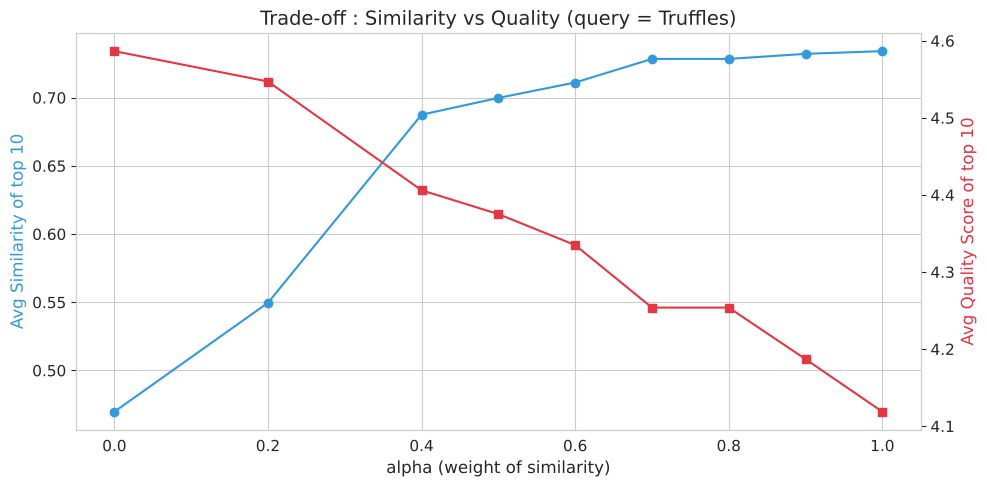

In [23]:
idx_truffles = find_restaurant("Truffles", "Koramangala 5Th Block")

alpha_rows = []
for a in [0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    recs = recommend_hybrid("Truffles", location="Koramangala 5Th Block", alpha=a, verbose=False)
    alpha_rows.append({"alpha": a, "avg_similarity": recs["similarity"].mean(), "avg_quality": recs["quality_score"].mean()})

alpha_df = pd.DataFrame(alpha_rows)

fig, ax1 = plt.subplots(figsize=(10,5))
ax1.plot(alpha_df["alpha"], alpha_df["avg_similarity"], "o-", color="#3498DB", label="avg similarity")
ax1.set_xlabel("alpha (weight of similarity)")
ax1.set_ylabel("Avg Similarity of top 10", color="#3498DB")

ax2 = ax1.twinx()
ax2.plot(alpha_df["alpha"], alpha_df["avg_quality"], "s-", color="#E23744", label="avg quality")
ax2.set_ylabel("Avg Quality Score of top 10", color="#E23744")
ax2.grid(False)

plt.title("Trade-off : Similarity vs Quality (query = Truffles)")
plt.tight_layout()
plt.savefig("plots/alpha_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

Classic **trade-off** :
- `alpha = 0` -> only quality -> very good restaurants, but less similar.
- `alpha = 1` -> only similarity -> very similar, but quality can drop.
- Somewhere in between (`0.6 - 0.8`) we get both. That's why we chose `0.7` ;)

------------------------------------------------------------------------------

# 4. Preference Based Search (no restaurant needed !)

Content based needs a restaurant the user already likes. What about a **new user** ? (cold start for users)

Solution : let the user describe what they want, convert that to the **same tag format**, and compare it with all restaurants
using the same TF-IDF + cosine similarity. Then apply hard filters (budget, location) and rank with the hybrid score.

In [24]:
def make_token(s):
    return s.strip().lower().replace(" ", "_").replace("&", "and").replace("-", "_").replace(".", "")


def recommend_for_user(cuisines=None, rest_type=None, location=None, max_cost=None,
                       online_order=None, book_table=None, n=10, alpha=0.6):

    # 1. build a query "tags" string, same format as restaurant tags
    tokens = []
    for c in (cuisines or []):
        tokens.append(make_token(c))
    for r in (rest_type or []):
        tokens.append("rt_" + make_token(r))
    if location:
        tokens.append("loc_" + make_token(location))

    query = " ".join(tokens)
    query_vec = tfidf.transform([query])

    # 2. similarity of query with all restaurants
    result = rest.copy()
    result["similarity"] = linear_kernel(query_vec, tfidf_matrix).flatten()

    # 3. hard filters
    if location:
        result = result[result["location"].str.lower() == location.lower()]
    if max_cost is not None:
        result = result[result["cost_for_two"] <= max_cost]
    if online_order is not None:
        result = result[result["online_order"] == int(online_order)]
    if book_table is not None:
        result = result[result["book_table"] == int(book_table)]

    result = result[result["similarity"] > 0]

    # 4. hybrid ranking
    result["hybrid_score"] = alpha * result["similarity"] + (1 - alpha) * result["quality_norm"]
    result = result.sort_values("hybrid_score", ascending=False)
    result = one_per_chain(result)

    print("Query tags: ", query)
    return result[show_cols + ["similarity", "hybrid_score"]].head(n).round(3).reset_index(drop=True)

#### Example 1 : *"Italian / Pizza in Indiranagar, under Rs.1000"*

In [25]:
recommend_for_user(cuisines=["Italian", "Pizza"], location="Indiranagar", max_cost=1000)

Query tags:  italian pizza loc_indiranagar


,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,similarity,hybrid_score
0,Bologna,Indiranagar,Casual Dining,Italian,1000.0,4.5,769,4.444,0.667,0.735
1,Onesta,Indiranagar,"Casual Dining, Cafe","Pizza, Cafe, Italian",600.0,4.3,4709,4.292,0.682,0.721
2,Mojo Pizza - 2X Toppings,Indiranagar,"Takeaway, Delivery",Pizza,600.0,4.3,203,4.160,0.605,0.656
3,Django,Indiranagar,Cafe,"Beverages, Italian, Pizza, Burger",800.0,4.0,220,3.927,0.631,0.638
4,Boozers Bar & Kitchen,Indiranagar,"Bar, Casual Dining","Continental, Burger, Italian, Pizza, Nort...",400.0,4.3,700,4.252,0.521,0.619
5,Pizza Hut,Indiranagar,Casual Dining,"Pizza, Fast Food",750.0,3.7,835,3.695,0.649,0.614
6,Pizza Joint Food Junction,Indiranagar,Quick Bites,"Fast Food, Pizza",350.0,3.1,8,3.556,0.679,0.612
7,Crispy Crust Pizza,Indiranagar,Delivery,Pizza,450.0,3.1,45,3.384,0.706,0.604
8,Power House Pitstsa,Indiranagar,Casual Dining,"Continental, Burger, Desserts, Sandwich, ...",800.0,NaN,0,3.877,0.543,0.577
9,The Twisted Desi,Indiranagar,Casual Dining,"Continental, Italian, North Indian, Chinese",1000.0,NaN,0,3.837,0.551,0.576


#### Example 2 : *"Pub with Finger Food in Koramangala 5th Block, with table booking"*

In [26]:
recommend_for_user(cuisines=["Finger Food"], rest_type=["Pub"], location="Koramangala 5Th Block", book_table=True)

Query tags:  finger_food rt_pub loc_koramangala_5th_block


,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,similarity,hybrid_score
0,Gilly'S Restobar,Koramangala 5Th Block,"Pub, Casual Dining","Finger Food, Continental, North Indian",1000.0,4.50,3923,4.488,0.728,0.777
1,Biergarten,Koramangala 5Th Block,"Pub, Microbrewery","Continental, North Indian, Chinese, Europ...",2100.0,4.80,524,4.692,0.525,0.686
2,What'S In A Name,Koramangala 5Th Block,Pub,"Finger Food, Asian, European, Italian",1200.0,4.10,1798,4.086,0.613,0.650
3,Bulls N Bears - Bar Trade Xchange,Koramangala 5Th Block,"Pub, Bar","Finger Food, North Indian, Continental, P...",1000.0,3.88,157,3.815,0.663,0.640
4,The Boozy Griffin,Koramangala 5Th Block,"Casual Dining, Pub","European, Continental",1800.0,4.60,5024,4.590,0.463,0.633
5,Beer Adda,Koramangala 5Th Block,"Casual Dining, Pub","North Indian, Chinese, Pizza",1000.0,4.27,554,4.214,0.553,0.632
6,Crawl Street,Koramangala 5Th Block,Bar,"Continental, Finger Food, North Indian, C...",1200.0,4.29,2589,4.277,0.449,0.580
7,Brooks And Bonds Brewery,Koramangala 5Th Block,"Casual Dining, Microbrewery","Continental, Mediterranean, North Indian,...",1600.0,4.47,3996,4.459,0.394,0.573
8,Chianti,Koramangala 5Th Block,Casual Dining,Italian,1500.0,4.70,4872,4.688,0.316,0.559
9,Sherlock'S Pub,Koramangala 5Th Block,"Pub, Casual Dining","Continental, North Indian, Chinese",1300.0,3.90,600,3.878,0.508,0.556


#### Example 3 : *"Cheap South Indian breakfast in Jayanagar, under Rs.300"*

In [27]:
recommend_for_user(cuisines=["South Indian"], rest_type=["Quick Bites"], location="Jayanagar", max_cost=300)

Query tags:  south_indian rt_quick_bites loc_jayanagar


,name,location,rest_type,cuisines,cost_for_two,rate,votes,quality_score,similarity,hybrid_score
0,Bengaluru Cafe,Jayanagar,Quick Bites,South Indian,150.0,4.45,135,4.217,0.878,0.828
1,Brahmin Tiffins & Coffee,Jayanagar,Quick Bites,South Indian,100.0,4.20,424,4.136,0.878,0.816
2,Davangere Benna Dose Hotel,Jayanagar,Quick Bites,South Indian,100.0,4.10,92,3.926,0.883,0.788
3,Iyengar'S Inn,Jayanagar,Quick Bites,South Indian,100.0,4.10,53,3.862,0.878,0.776
4,Shree Venkateshwara North Karnataka Hotel,Jayanagar,Quick Bites,South Indian,200.0,4.00,82,3.853,0.878,0.775
5,Sangam Military Hotel,Jayanagar,Quick Bites,South Indian,250.0,3.23,14,3.542,0.932,0.762
6,New Select Hotel,Jayanagar,Quick Bites,South Indian,150.0,NaN,0,3.762,0.878,0.762
7,Sri Sai 99 Variety Dosa,Jayanagar,Quick Bites,South Indian,300.0,3.60,38,3.614,0.911,0.760
8,Sri Udupi Veg,Jayanagar,Quick Bites,South Indian,250.0,3.37,4,3.606,0.911,0.759
9,Vybhava,Jayanagar,Quick Bites,"South Indian, North Indian",250.0,3.80,39,3.699,0.887,0.758


------------------------------------------------------------------------------

# 5. Evaluation

### Problem : How do we evaluate a recommender without real users ? :/

In real companies they use A/B testing & click-through-rate. We don't have that, so we use **offline proxy metrics**.

For 500 random rated restaurants (as "liked" restaurants), we take the top 10 recommendations and calculate :

| Metric | Meaning | Good if |
|---|---|---|
| `cuisine_overlap` | Jaccard similarity b/w cuisines of liked restaurant & recommended ones | high (relevance) |
| `same_price_cat` | % recs in same price category | high (relevance) |
| `avg_quality` | avg `quality_score` of recs | high (are recs good restaurants ?) |
| `coverage` | % of all restaurants that appear in at least one rec list | high (not always the same famous places) |
| `new_rest_share` | % of recs that are NEW (unrated) restaurants | > 0 (cold start items get a chance) |

We compare 4 methods :
1. **Random** (lower bound)
2. **Popularity** (top quality restaurants of the same location)
3. **Content based** (pure similarity)
4. **Hybrid**

In [28]:
rest["cuisine_set"] = rest["cuisines"].apply(lambda s: set(x.strip() for x in s.split(",")))


def jaccard(a, b):
    return len(a & b) / len(a | b) if len(a | b) > 0 else 0


rng = np.random.RandomState(42)
query_ids = rng.choice(rest[rest["is_rated"] == 1].index, size=500, replace=False)

# precomputing top quality restaurants per location for the popularity method
top_by_loc = (
    rest.sort_values("quality_score", ascending=False)
    .groupby("location")
    .head(30)
    .groupby("location")
    .apply(lambda d: list(d.index))
)


def top_unique(sorted_index, n):
    # keep first n indices with unique names (same as one_per_chain)
    names = rest.loc[sorted_index, "name"]
    return list(names[~names.duplicated()].index[:n])


def recs_random(idx, n=10):
    pool = rest.index[rest["name"] != rest.loc[idx, "name"]]
    return list(rng.choice(pool, size=n, replace=False))


def recs_popular(idx, n=10):
    cand = [i for i in top_by_loc[rest.loc[idx, "location"]] if rest.loc[i, "name"] != rest.loc[idx, "name"]]
    return top_unique(cand, n)


def recs_content(idx, n=10):
    sim = get_similarity(idx)
    tmp = pd.DataFrame({"sim": sim, "q": rest["quality_score"]})
    tmp = tmp[rest["name"] != rest.loc[idx, "name"]]
    return top_unique(tmp.sort_values(["sim", "q"], ascending=False).head(100).index, n)


def recs_hybrid(idx, n=10, alpha=0.7, min_sim=0.3):
    sim = get_similarity(idx)
    tmp = pd.DataFrame({"sim": sim, "q": rest["quality_norm"]})
    tmp = tmp[(rest["name"] != rest.loc[idx, "name"]) & (tmp["sim"] >= min_sim)]
    tmp["score"] = alpha * tmp["sim"] + (1 - alpha) * tmp["q"]
    return top_unique(tmp.sort_values("score", ascending=False).head(100).index, n)

In [29]:
def evaluate_method(rec_func):
    overlap, same_price, quality, new_share = [], [], [], []
    all_recs = set()

    for idx in query_ids:
        recs = rec_func(idx)
        if len(recs) == 0:
            continue
        all_recs.update(recs)
        q_cuis = rest.loc[idx, "cuisine_set"]
        overlap.append(np.mean([jaccard(q_cuis, rest.loc[r, "cuisine_set"]) for r in recs]))
        same_price.append(np.mean([rest.loc[r, "price_category"] == rest.loc[idx, "price_category"] for r in recs]))
        quality.append(rest.loc[recs, "quality_score"].mean())
        new_share.append((rest.loc[recs, "is_rated"] == 0).mean())

    return {
        "cuisine_overlap" : np.mean(overlap),
        "same_price_cat" : np.mean(same_price),
        "avg_quality" : np.mean(quality),
        "coverage" : len(all_recs) / len(rest),
        "new_rest_share" : np.mean(new_share),
    }


methods = {
    "Random" : recs_random,
    "Popularity (same loc)" : recs_popular,
    "Content Based" : recs_content,
    "Hybrid" : recs_hybrid,
}

eval_df = pd.DataFrame({name: evaluate_method(f) for name, f in methods.items()}).T.round(3)
eval_df

,cuisine_overlap,same_price_cat,avg_quality,coverage,new_rest_share
Random,0.113,0.361,3.663,0.330,0.232
Popularity (same loc),0.100,0.224,4.351,0.057,0.003
Content Based,0.569,0.784,3.667,0.310,0.210
Hybrid,0.570,0.770,3.782,0.297,0.164


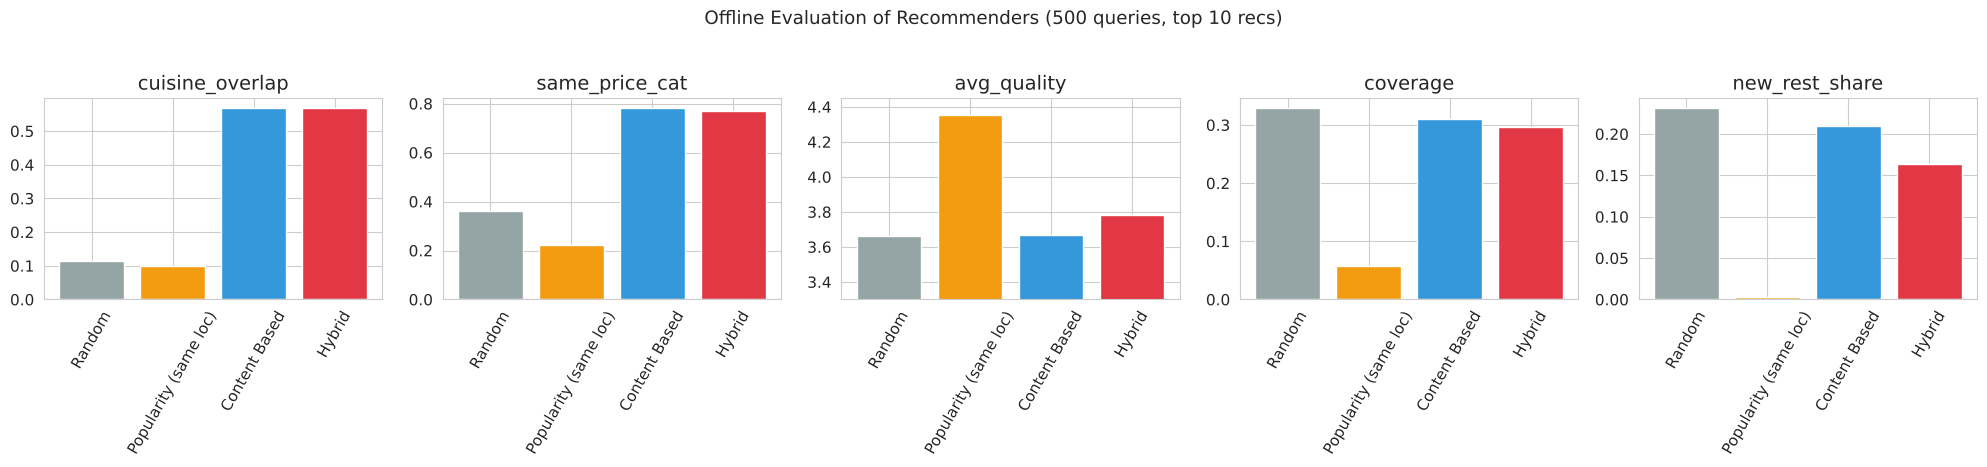

In [30]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

colors = ["#95A5A6", "#F39C12", "#3498DB", "#E23744"]
for ax, metric in zip(axes, eval_df.columns):
    ax.bar(eval_df.index, eval_df[metric], color=colors)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=60)

    # quality scores are all around 3.5 - 4.5, zooming in so the difference is visible
    if metric == "avg_quality":
        ax.set_ylim(3.3, eval_df[metric].max() + 0.1)

plt.suptitle("Offline Evaluation of Recommenders (500 queries, top 10 recs)", y=1.03)
plt.tight_layout()
plt.savefig("plots/recommender_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

-------------------------------------------------------
### Insights (Evaluation) :

- **Random** is useless (as expected) -> cuisine overlap only ~0.11. It's only there as a lower bound.
- **Popularity** gives the highest quality restaurants (avg ~4.35), but relevance is even *worse than random* (a dosa lover gets brewpubs !)
  and coverage is only ~6% -> the same few famous places are recommended to everyone (**popularity bias**). Almost no NEW restaurant ever appears (0.3%).
- **Content based** gives high relevance (cuisine overlap ~0.57, ~78% same price category), but avg quality (~3.67) is no better than random.
- **Hybrid** keeps the **same relevance** as content based (0.57), while improving the avg quality from ~3.67 -> ~3.78.
  Coverage stays high (~30%) and ~16% of recommendations are still NEW restaurants (thanks to the predicted rating from Part 4).
  -> best balance, so this is our **final recommender** ;)

-------------------------------------------------------

------------------------------------------------------------------------------

# Final Summary of the Project

```
Part 1 : Zomato_EDA.ipynb                 -> cleaning + univariate analysis
Part 2 : 02_..._Bivariate_Multivariate    -> relationships, what affects ratings
Part 3 : 03_Feature_Engineering           -> restaurant level data, weighted rating, tags
Part 4 : 04_Rating_Prediction_Models      -> ML model to predict rating of NEW restaurants
Part 5 : 05_Recommendation_System         -> popularity, content, hybrid, preference based recs
```

### What we built :
1. **Popularity recommender** : best restaurants for given filters (location / cuisine / budget).
2. **Content based recommender** : TF-IDF on tags + cosine similarity -> "*similar to X*".
3. **Hybrid recommender** : similarity + quality score (`alpha = 0.7`) -> relevant **and** good.
4. **Preference based search** : for new users, query built from what they like.

### Limitations :
- No user data -> no collaborative filtering / real personalisation.
- Evaluation is offline (proxy metrics), not real user feedback.
- Data is a snapshot (2019), ratings could have changed a lot.
- We removed `reviews_list`, `dish_liked`, `menu_item` in Part 1. They have tons of useful info.

### Future work :
- Use **NLP on reviews** (sentiment, dish mentions) -> better tags & better quality score.
- Use reviewer names inside `reviews_list` as pseudo user ids -> try **collaborative filtering** (matrix factorization / SVD).
- Build a small **Streamlit** web app on top of `recommend_hybrid()` & `recommend_for_user()`.